# Câu 3: Khảo sát sự liên quan giữa Độ tuổi (age), Tình trạng hôn nhân (marital) và khả năng đăng ký (y)

Phần 1 – Bài 2 (trang 28): Khảo sát và tiền xử lý dữ liệu Bank marketing giống phần hướng dẫn.

Dữ liệu dùng: `bank-full.csv` (45.211 khách hàng, 16 thuộc tính + thuộc tính quyết định `y` – có đăng ký gửi tiền có kỳ hạn hay không).

In [1]:
SV = "Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT"
DATA = "../../data/"  # thư mục chứa dữ liệu
print(SV)

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


In [2]:
import re
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

### Chuẩn bị: thực hiện lại các bước của các câu trước

In [3]:
df = pd.read_csv(DATA + 'bank-full.csv', sep=';')
df['y_num'] = (df['y'] == 'yes').astype(int)   # dùng để tính tỷ lệ đăng ký

---
## Thực hiện yêu cầu

Họ tên: Mai Quốc Đại - MSSV: 6451071013 - Lớp: CQ.64.CNTT


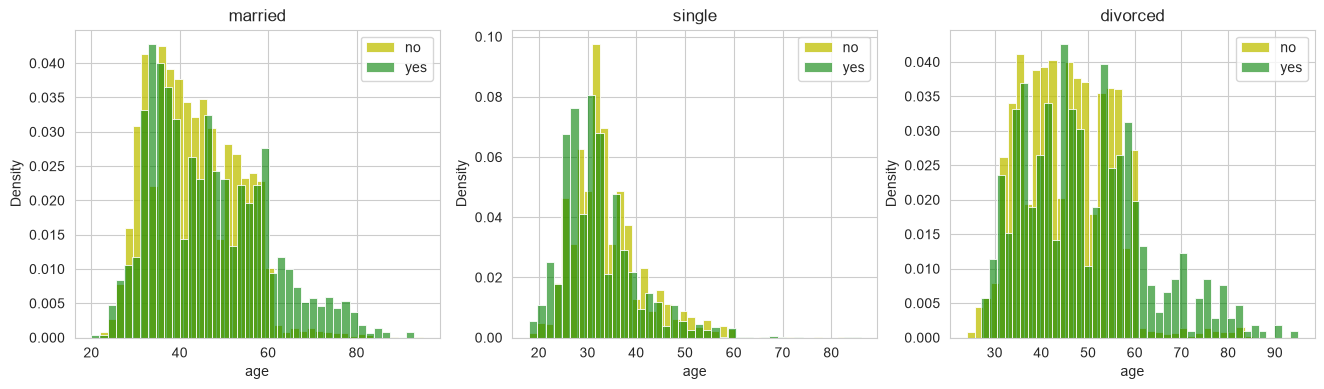

In [4]:
print(SV)
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(16, 4))
for ax, m in zip(axes, ['married', 'single', 'divorced']):
    d = df[df['marital'] == m]
    sns.histplot(d[d['y'] == 'no']['age'], bins=40, label='no', ax=ax, color='y', stat='density')
    sns.histplot(d[d['y'] == 'yes']['age'], bins=40, label='yes', ax=ax, color='g', stat='density', alpha=.6)
    ax.legend(); ax.set_title(m)
plt.show()

In [5]:
age_group = pd.cut(df['age'], bins=[17, 25, 30, 40, 50, 60, 95])
pd.crosstab(age_group, df['marital'], values=df['y_num'], aggfunc='mean').round(3)

marital,divorced,married,single
age,,,
"(17, 25]",0.000,0.144,0.257
"(25, 30]",0.110,0.083,0.178
"(30, 40]",0.102,0.092,0.121
"(40, 50]",0.100,0.083,0.123
"(50, 60]",0.113,0.097,0.107
"(60, 95]",0.487,0.415,0.265


In [6]:
df.groupby('marital')['y_num'].agg(['count', 'mean']).round(3)

,count,mean
marital,,
divorced,5207,0.119
married,27214,0.101
single,12790,0.149


**Nhận xét:**

- Phân bố tuổi của nhóm đăng ký (yes) và không đăng ký (no) gần như trùng nhau ở khoảng 25–60 tuổi; khác biệt rõ ở hai đầu.
- Khách trên 60 tuổi có tỷ lệ đăng ký rất cao (≈27–49%), cao nhất ở nhóm đã ly hôn/góa (≈49%) và đã kết hôn (≈42%), phần lớn là người đã nghỉ hưu.
- Khách độc thân trẻ (≤ 25 tuổi) cũng đăng ký nhiều (≈26%); khách 30–60 tuổi chỉ ≈8–12%.
- Theo tình trạng hôn nhân: độc thân đăng ký nhiều nhất (14,9%), sau đó ly hôn (11,9%), đã kết hôn thấp nhất (10,1%).